# Heart Disease — EDA & Model Development

BITS MLOps Assignment 01. Reproduces EDA and training interactively. Production logic lives in `src/` (source of truth); this notebook is for exploration and grading visibility.


In [1]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
# Work from the repo root whether the notebook is opened from / or notebooks/
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd, numpy as np
from preprocessing import (ALL_FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES,
                           TARGET, basic_clean, load_raw, build_preprocessor, split_X_y)


## 1. Load & clean

In [2]:
df = basic_clean(load_raw('data/heart_raw.csv'))
print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
df[TARGET].value_counts(normalize=True).rename('ratio')

target
0    0.541254
1    0.458746
Name: ratio, dtype: Float64

In [4]:
df[ALL_FEATURES].isna().sum().sum()  # missing values after cleaning

np.int64(6)

## 2. EDA visualisations
Full figures: `python src/eda.py`. Inline quick view:

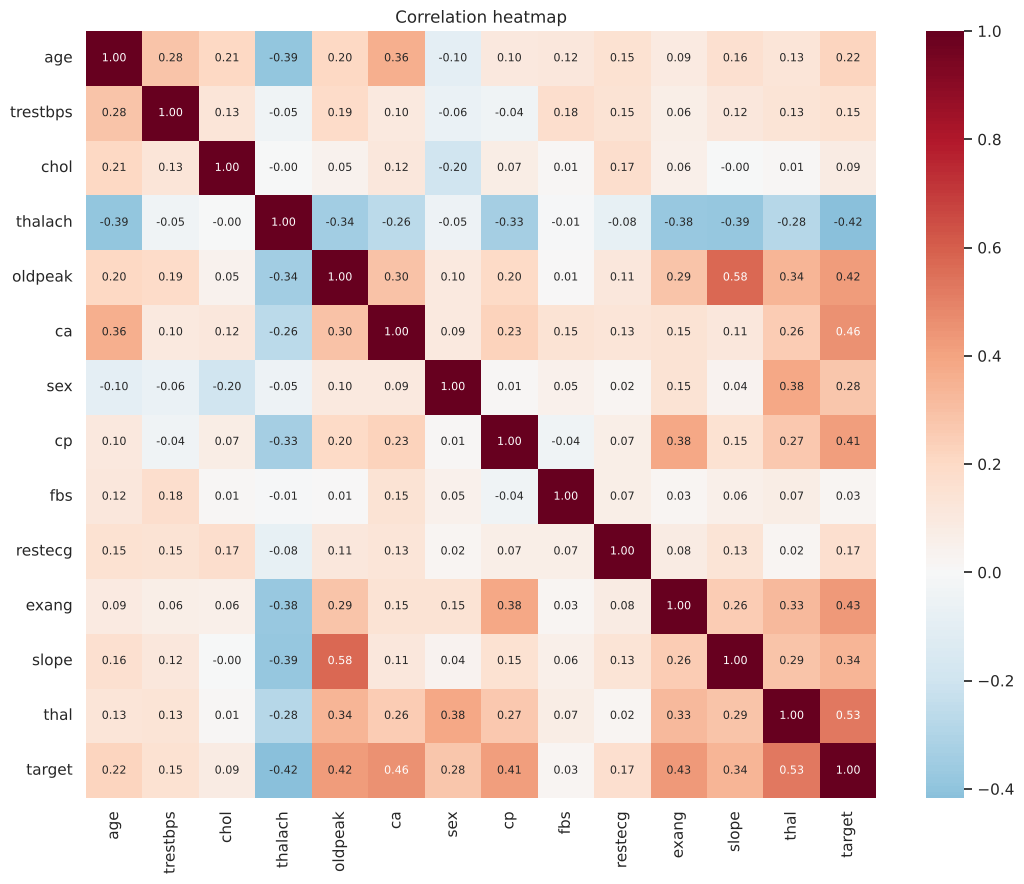

In [5]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid')
corr = df[ALL_FEATURES+[TARGET]].corr()
plt.figure(figsize=(11,9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size':8})
plt.title('Correlation heatmap'); plt.tight_layout(); plt.show()

In [6]:
corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(8)

thal       0.525689
ca         0.460442
exang      0.431894
oldpeak    0.424510
thalach   -0.417167
cp         0.414446
slope      0.339213
sex        0.276816
Name: target, dtype: float64

## 3. Train / tune / evaluate
Full tracked pipeline: `python src/train.py`. Inline quick model:

In [7]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, classification_report
X, y = split_X_y(df)
Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)
pipe = Pipeline([('pre', build_preprocessor()),
                 ('clf', RandomForestClassifier(n_estimators=200, max_depth=5,
                         min_samples_leaf=4, class_weight='balanced', random_state=42))])
cv = StratifiedKFold(5, shuffle=True, random_state=42)
print('CV ROC-AUC:', cross_val_score(pipe, Xtr, ytr, cv=cv, scoring='roc_auc').mean().round(4))
pipe.fit(Xtr,ytr)
print('hold-out ROC-AUC:', round(roc_auc_score(yte, pipe.predict_proba(Xte)[:,1]),4))
print(classification_report(yte, pipe.predict(Xte)))

CV ROC-AUC: 0.8971


hold-out ROC-AUC: 0.9513
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        33
           1       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



## 4. Inference example

In [8]:
import joblib
m = joblib.load('model_artifacts/model.joblib')
row = pd.DataFrame([{'age':67,'sex':1,'cp':4,'trestbps':160,'chol':286,'fbs':0,
    'restecg':2,'thalach':108,'exang':1,'oldpeak':1.5,'slope':2,'ca':3,'thal':3}])[ALL_FEATURES]
print('prediction:', int(m.predict(row)[0]), 'P(disease):', round(float(m.predict_proba(row)[0,1]),4))

prediction: 1 P(disease): 0.9818
